# Session 14 · Case study: embedding features versus TF-IDF, and nearest-neighbour search

**Block 1, worked example.** Compare frozen multilingual sentence embeddings with TF-IDF as classification features on the same subsample, and build a nearest-neighbour search over decisions in several languages.

Uses `sentence-transformers` from the course environment (the first run downloads `intfloat/multilingual-e5-small`, about 470 MB). Encoding 12,000 descriptions takes about a minute on a laptop; the vectors are cached in `embeddings_cache/` next to this notebook.

Theory: [01-lecture-embeddings-from-words-to-vectors.ipynb](01-lecture-embeddings-from-words-to-vectors.ipynb), second half. Exercises: [session-14-exercises.ipynb](session-14-exercises.ipynb), part 1.

*Author: course team, licence CC-BY-4.0.*

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# find the repository root (the folder that contains case-study/), wherever the notebook runs
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").exists())
DATA = ROOT / "case-study" / "data"
decisions = pd.read_parquet(DATA / "train_sample.parquet")
nomenclature = pd.read_parquet(DATA / "nomenclature.parquet").set_index("heading")
print(decisions.shape)

(50000, 14)


In [2]:
from sentence_transformers import SentenceTransformer

MODEL_NAME = "intfloat/multilingual-e5-small"
year = decisions["start_date"].dt.year
train = decisions[year <= 2021].sample(10_000, random_state=0)      # validation by time
valid = decisions[year >= 2022].sample(2_000, random_state=0)
model = SentenceTransformer(MODEL_NAME)

cache = Path("embeddings_cache")
cache.mkdir(exist_ok=True)


def embed(name, docs, prefix):
    """Encode once, then load from disk; the file name records model, prefix and split."""
    path = cache / f"{MODEL_NAME.split('/')[-1]}_{prefix.strip(': ')}_{name}.npy"
    if path.exists():
        return np.load(path)
    E = model.encode((prefix + docs).tolist(), batch_size=64, normalize_embeddings=True, show_progress_bar=False)
    np.save(path, E)
    return E


E_tr = embed("train", train["description"], "passage: ")
E_va = embed("valid", valid["description"], "query: ")
print(E_tr.shape, E_va.shape)

.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8262.06it/s]

(10000, 384) (2000, 384)


## 1. Three representations, one classifier

In [3]:
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score


def svm():
    return SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0, n_jobs=-1)


vec = TfidfVectorizer(min_df=2, sublinear_tf=True).fit(train["description"])
T_tr, T_va = vec.transform(train["description"]), vec.transform(valid["description"])
features = {
    "tf-idf": (T_tr, T_va),
    "embeddings": (E_tr, E_va),
    "both": (hstack([T_tr, csr_matrix(E_tr)]).tocsr(), hstack([T_va, csr_matrix(E_va)]).tocsr()),
}
rows = []
for name, (A_tr, A_va) in features.items():
    pred = svm().fit(A_tr, train["heading"]).predict(A_va)
    rows.append({"features": name, "accuracy": accuracy_score(valid["heading"], pred),
                 "macro_F1": f1_score(valid["heading"], pred, average="macro"),
                 "chapter_accuracy": np.mean(pd.Series(pred).str[:2].to_numpy() == valid["chapter"].to_numpy())})
pd.DataFrame(rows).round(3)

,features,accuracy,macro_F1,chapter_accuracy
0,tf-idf,0.662,0.411,0.759
1,embeddings,0.566,0.303,0.693
2,both,0.675,0.423,0.780


## 2. Learning curve: does the number of labels change the winner?

A 1-nearest-neighbour classifier needs no tuning, so it compares the two representations directly.

,embeddings 1-NN,tf-idf 1-NN
n_train,,
500,0.270,0.338
2000,0.400,0.474
5000,0.509,0.580
10000,0.560,0.624


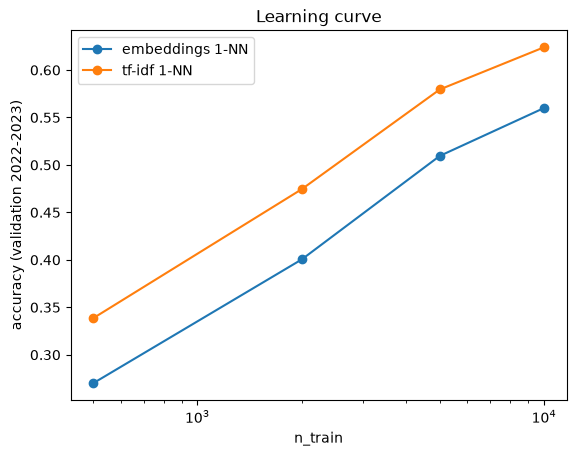

In [4]:
rng = np.random.default_rng(0)
heads, truth = train["heading"].to_numpy(), valid["heading"].to_numpy()
curve = []
for n in [500, 2000, 5000, len(train)]:
    idx = rng.choice(len(train), n, replace=False)
    emb = heads[idx][np.argmax(E_va @ E_tr[idx].T, axis=1)]
    v = TfidfVectorizer(sublinear_tf=True).fit(train["description"].iloc[idx])
    sims = v.transform(valid["description"]) @ v.transform(train["description"].iloc[idx]).T
    tf = heads[idx][np.asarray(sims.argmax(axis=1)).ravel()]
    curve.append({"n_train": n, "embeddings 1-NN": np.mean(emb == truth), "tf-idf 1-NN": np.mean(tf == truth)})
curve = pd.DataFrame(curve).set_index("n_train")
ax = curve.plot(marker="o", logx=True, ylabel="accuracy (validation 2022-2023)", title="Learning curve")
curve.round(3)

**Question.** For English sentiment classification, pre-trained embeddings usually win when only a few hundred labels exist. Why not here? (Hint: how many of the 900 headings have at least one example among 500 training decisions?)

## 3. Nearest-neighbour search across languages

In [5]:
german = (train["language"] == "de").to_numpy()
corpus = train[german].reset_index(drop=True)
E_de = E_tr[german]
kw = TfidfVectorizer(min_df=2, sublinear_tf=True).fit(corpus["description"])
K = kw.transform(corpus["description"])


def search(query, k=5):
    q = model.encode("query: " + query, normalize_embeddings=True)
    out = []
    for method, scores in [("embedding", E_de @ q),
                           ("tf-idf", (K @ kw.transform([query]).T).toarray().ravel())]:
        for rank, i in enumerate(np.argsort(-scores)[:k], start=1):
            out.append({"method": method, "rank": rank, "score": round(float(scores[i]), 2),
                        "heading": corpus["heading"][i], "keywords": str(corpus["keywords"][i])[:60],
                        "description": corpus["description"][i][:90]})
    return pd.DataFrame(out)


pd.set_option("display.max_colwidth", 100)
search("disposable face masks")

,method,rank,score,heading,keywords,description
0,embedding,1,0.81,6307,"COTTON,FACE MASKS,FINE KNIT FABRICS,MASKS,OF MAN-MADE FIBRE,","Mund-/Nasenbedeckung, sog. Sublistar® Gesichtsmaske weiß, Artikel-Nr. MASK-2-L und MASK-2-"
1,embedding,2,0.80,3401,"CLEANING CLOTHS,FACE,IMPREGNATED,NONWOVENS,SKIN,SKINCARE PRE","Angaben: \nPflegende Reinigungstücher, 25 Stück, für die schnelle, optimale Reinigung des G"
2,embedding,3,0.80,3401,"CLEANING CLOTHS,DETERGENTS,FOR DOMESTIC USE,IMPREGNATED,NONW","Angaben: \nWaschmaschinenreinigungstuch.\n\nWarenbeschreibung: \nWeißes, duftendes Vliestuch ("
3,embedding,4,0.80,3214,"BINDING SUBSTANCE,DISPERSION,PIGMENTS,POLYMERS,WATER,WHITE",Angaben: \nBrandschutzfarbe; wässrige Dispersion für die intumeszierende Brandschutzbeschic
4,embedding,5,0.79,9033,"MASKS,OF PLASTICS,OF SILICONE,RESPIRATORY MASKS,SECTIONS","Sog. Dahlhausen Silikonmasken, in Form einer je nach Ausführung runden oder annähernd oval"
5,tf-idf,1,0.00,9018,"HOSES,MEDICAL INSTRUMENTS,OF METAL,OF PLASTICS,STETHOSCOPES","Stethoskop, sog. Schwestern-Stethoskop, in vier verschiedenen Farben, im Wesentlichen best"
6,tf-idf,2,0.00,9403,"CONTAINERS,FURNITURE,OF BASE METALS,OF METAL,UMBRELLAS","Es handelt sich bei dem sog. ""Artikel Nr. 17714 Schirmständer, Mesh"" um ein Möbel aus Meta"
7,tf-idf,3,0.00,0604,"DRIED,DYED,MOSSES,WIRES,YARNS","""Rattanherz""\n- herzförmiges, dreidimensionales Gerüst aus Metalldraht (ohne eigene Zierwir"
8,tf-idf,4,0.00,9031,"ANGLES,ELECTRIC,GAUGES,HOUSINGS,LED,SCIENTIFIC AND MEASURING","Winkelmessgerät, sog. Multiturn-Drehgeber (EnDAT 2.2), im Wesentlichen bestehend aus einem"
9,tf-idf,5,0.00,8428,"ELECTRIC MOTORS,ENGINES,HOUSINGS,MECHANICAL,PLATFORMS,VOLTAG",Funktionelle Einheit zum Testen von Fahrzeugassistenzsystemen (z. B. autonome Notbrems- od


In [6]:
search("children's bicycle helmet")

,method,rank,score,heading,keywords,description
0,embedding,1,0.8,9503,"FOR CHILDREN,OF PLASTICS,PAWNS,TOYS","Spielzeug, sog. ""Mc Donald's - Despicable Me - 3 - 2017, Bite your Tongue Minion"",\n- aus K"
1,embedding,2,0.8,6114,"GOODS PUT UP IN SETS,MADE UP,OF MAN-MADE FIBRE,OVERALLS,TWO-","Kinderkostüm Skelett, sog. Jungenkostüm Skeleton, Größe 8-10 Jahre (entspricht den Größen"
2,embedding,3,0.8,6404,"OF PLASTICS,OF TEXTILE MATERIAL,OUTER SOLES,SHOES,UPPERS, FO","Babyschuhe, Art. 2302015, Gr. 17/18, Foto siehe Anlage\n- mit Laufsohlen aus (lt. Antrag) K"
3,embedding,4,0.8,9503,"FOR CHILDREN,OF BASE METALS,OF PLASTICS,OF WOOD,PULL-BACK MO","Spielzeugauto mit eingebautem Motor, sog. ""Holzrennauto mit Rückzug, Artikel-Nr.: 349 000"""
4,embedding,5,0.8,9503,"ANIMALS,FOR CHILDREN,OF PLASTICS,ROTARY,SPINNING TOPS,TOYS","Zusammengesetzte Ware in Form eines Kreisels, sog. ""Mc Donald's Spielzeug - Snoopy 2018"","
5,tf-idf,1,0.0,9018,"HOSES,MEDICAL INSTRUMENTS,OF METAL,OF PLASTICS,STETHOSCOPES","Stethoskop, sog. Schwestern-Stethoskop, in vier verschiedenen Farben, im Wesentlichen best"
6,tf-idf,2,0.0,9403,"CONTAINERS,FURNITURE,OF BASE METALS,OF METAL,UMBRELLAS","Es handelt sich bei dem sog. ""Artikel Nr. 17714 Schirmständer, Mesh"" um ein Möbel aus Meta"
7,tf-idf,3,0.0,0604,"DRIED,DYED,MOSSES,WIRES,YARNS","""Rattanherz""\n- herzförmiges, dreidimensionales Gerüst aus Metalldraht (ohne eigene Zierwir"
8,tf-idf,4,0.0,9031,"ANGLES,ELECTRIC,GAUGES,HOUSINGS,LED,SCIENTIFIC AND MEASURING","Winkelmessgerät, sog. Multiturn-Drehgeber (EnDAT 2.2), im Wesentlichen bestehend aus einem"
9,tf-idf,5,0.0,8428,"ELECTRIC MOTORS,ENGINES,HOUSINGS,MECHANICAL,PLATFORMS,VOLTAG",Funktionelle Einheit zum Testen von Fahrzeugassistenzsystemen (z. B. autonome Notbrems- od


The keywords (English, assigned by customs) let you check whether the German hits are relevant.

## 4. Nearest neighbours of a decision

The same index answers "which decisions are most similar to this one?", for example to find decisions of other member states on similar goods.

In [7]:
from sklearn.neighbors import NearestNeighbors

nn = NearestNeighbors(n_neighbors=5, metric="cosine").fit(E_tr)
i = 10
print(valid["language"].iloc[i], valid["heading"].iloc[i], valid["description"].iloc[i][:120], "\n")
dist, ind = nn.kneighbors(E_va[[i]])
for d, j in zip(dist[0], ind[0]):
    print(f"{1 - d:.2f}  {train['language'].iloc[j]}  {train['heading'].iloc[j]}  {train['description'].iloc[j][:90]}")

de 8517 RJ45-Übertrager-Modul (Abbildung siehe Anlage)
- aus einer mit mehreren Transformatoren, stromkompensierenden Drosseln,
 

0.97  de  8517  RJ-45-Übertrager-Modul (Abbildung siehe Anlage)
- aus einer mit mehreren Transformatoren, 
0.96  de  8517  RJ45-Übertrager-Modul
- aus einer mit mehreren Transformatoren, stromkompensierenden Dross
0.90  de  8517  Übertrager-Modul
- aus zwei 1:1 Übertragern, die jeweils mit einer stromkompensierten Dros
0.89  de  8517  WLAN-Präsentations-Gateway (Abbildung siehe Anlage)
- aus einer mit WLAN-Modul, Signalelek
0.89  de  8517  Funkempfänger (Abbildung siehe Anlage)
- aus einer mit Funkempfangsmodul und weiteren Baue
